[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/17_whitening_recovered_image.ipynb)

# Whitening: what the denoiser recovers of the image at each noise scale

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Take a whitened image, add more and more noise to it, and denoise each noisy version with the model of the whitened images (notebook 16). Then undo the whitening (smoothing with the inverse of the whitening filter) on each denoised image and on the whitened image itself, to see what the denoiser recovers of the original image at each noise scale.

* **Requirements**: TinyImageNet, the model of the whitened images and the whitening filter of notebook 16 (`runs/diffusion/unconditional/tinyimagenet-whitened/`, `data/02_intermediate/16_whitening/filter.pt`), a GPU, and `multigeom` from the `g-per-scale` branch.

* **Time**: under a minute on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub: on Google Colab always (with `diffusers`), elsewhere only if the installed one lacks its functions.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom.config": {"load_config": []},
        "multigeom.datasets": {
            "WhiteningFilter": [],
            "download_tinyimagenet": [],
            "load_examples": [],
        },
        "multigeom.diffusion": {"compute_denoised": []},
        "multigeom.diffusion.model": {
            "build_diffusion_model": [],
            "build_scheduler": [],
        },
        "multigeom.plotting": {"plot_recovered": []},
        "multigeom.utils": {"get_device": []},
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

CPU times: user 3.07 s, sys: 87.2 ms, total: 3.16 s
Wall time: 630 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the example images, the noise scales, the regularisation of the inverse filter, and where the figures go.

<details><summary>Details</summary>

* `WhiteningFilter.invert` un-whitens images with the regularised (Wiener) inverse of the whitening filter, $K / (K^2 + \lambda)$: about $1/K$ where the filter passes the image, and 0 where it removed it. The mean of each image (frequency 0, where $K = 0$) cannot be recovered, so the images are compared with their mean removed.
* `compute_denoised` gives the denoised image $\hat x(x_t)$ by Tweedie's formula from the null token of a diffusion model (notebook 16); `plot_recovered` draws the figure of one image.

</details>

In [2]:
%%time

import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import WhiteningFilter, download_tinyimagenet, load_examples
from multigeom.diffusion import compute_denoised
from multigeom.diffusion.model import build_diffusion_model, build_scheduler
from multigeom.plotting import plot_recovered
from multigeom.utils import get_device

# the parameters of this notebook
PARAMS = {
    # the example images of notebooks 8 and 16 (the frog, then test images by index),
    # and 20 more test images: the first ones not among them
    "frog": "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG",
    "test_images": [0, 3, 9, 16, 27, 41, 58, 72, 95, 118, 150, 187]
    + [1, 2, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 17, 18, 19, 20, 21, 22, 23],
    # the model of the whitened images and the whitening filter (notebook 16)
    "whitened_model": "runs/diffusion/unconditional/tinyimagenet-whitened",
    "filter": "data/02_intermediate/16_whitening/filter.pt",
    # the DDPM steps of the noise scales, from almost no noise to almost only noise
    "steps": [5, 20, 40, 100, 200, 300, 400, 500, 600, 700, 800, 950],
    # the regularisation λ of the inverse filter (the gain is 1 at its peak): smaller
    # recovers more of the lowest frequencies, and amplifies their errors more
    "regularization": 1e-3,
    # the images whose figures stay in the notebook, and where the figures are saved,
    # with their resolution in the file and on screen
    "show": ["frog", "img0027"],
    "figure_dir": "assets/figures/stimulus_whitening/recovered_image",
    "file_dpi": 200,
    "screen_dpi": 100,
}

# the diffusion and estimator configs (packaged with multigeom), and the device
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 988 ms, sys: 137 ms, total: 1.12 s
Wall time: 1.13 s


## 2. Download datasets

TinyImageNet gives the example images (240 MB the first time). The model of the whitened images is trained by `scripts/train_whitened_diffusion.py` (notebook 16).

In [3]:
%%time

# TinyImageNet (nothing if already there)
download_tinyimagenet()

CPU times: user 90 μs, sys: 0 ns, total: 90 μs
Wall time: 75.1 μs


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 3. Load the whitening filter and the model of the whitened images

In [4]:
%%time

# 1. the whitening filter of notebook 16
whitening = WhiteningFilter.from_state_dict(torch.load(PARAMS["filter"]))

# 2. the model of the whitened images (its null token), and the noise schedule
model_dir = Path(PARAMS["whitened_model"])
unet = build_diffusion_model(diff_cfg).to(device)
stored = torch.load(
    model_dir / "final_model.pt", map_location=device, weights_only=False
)
unet.load_state_dict(stored["model_state_dict"])
unet.eval()
alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)
print(whitening.state_dict())

{'cutoff': 0.4, 'scale': 2.933501482363829, 'pad': 16}
CPU times: user 296 ms, sys: 197 ms, total: 493 ms
Wall time: 498 ms


## 4. Noise, denoise and un-whiten each example image

For each image: whiten it, add noise of variance $t$ at each noise scale, denoise each noisy version, and un-whiten each denoised image. How much of the image is recovered is measured by the correlation of the un-whitened denoised image with the image, both with their mean removed; the whitened image un-whitened gives the best that the inverse filter allows.

<details><summary>Details</summary>

* **Noise.** $x_t = \sqrt{\bar\alpha}\, x + \sqrt{1 - \bar\alpha}\, \epsilon$ with one seeded draw $\epsilon$ per image and noise scale; the noise scale is $\tau = \log t$, $t = (1 - \bar\alpha)/\bar\alpha$, as in notebooks 7 to 10.
* **Denoised image.** $\hat x(x_t) = \mathbb{E}[x \mid x_t]$, the posterior mean: at coarse noise scales it is a blurred guess, not a sample, so it is smooth by construction.

</details>

In [5]:
%%time

# 1. the example images, whitened and un-whitened
examples = load_examples(PARAMS, int(est_cfg.seed))
generator = torch.Generator(device=device).manual_seed(int(est_cfg.seed))


def get_correlation(first: torch.Tensor, second: torch.Tensor) -> float:
    """The correlation of two images, each with its mean removed."""
    a, b = first.double().flatten(), second.double().flatten()
    a, b = a - a.mean(), b - b.mean()
    return float((a @ b) / (a.norm() * b.norm()))


# 2. for each image and noise scale: the noisy whitened image, the denoised one, and
# that un-whitened; and its correlation with the image
recovered, correlations, references = {}, {}, {}
with torch.no_grad():
    for name, (image, _) in examples.items():
        white = whitening(image).to(device)
        references[name] = whitening.invert(white.cpu(), PARAMS["regularization"])
        recovered[name], correlations[name] = {}, {}
        for t_j in PARAMS["steps"]:
            ab = alphas_cumprod[t_j]
            noise = torch.randn(white.shape, device=device, generator=generator)
            x_t = ab.sqrt() * white + (1 - ab).sqrt() * noise
            x_hat = compute_denoised(unet, x_t, t_j, alphas_cumprod)[0].cpu()
            back = whitening.invert(x_hat, PARAMS["regularization"])
            scale = float(((1 - ab) / ab).log())
            recovered[name][scale] = (x_t.cpu(), x_hat, back)
            correlations[name][scale] = get_correlation(back, image)

# 3. the correlations: per noise scale, the mean over the images, and the ceiling
# (the whitened image un-whitened)
ceiling = np.mean([get_correlation(references[n], examples[n][0]) for n in examples])
print(f"whitened image un-whitened: correlation {ceiling:.3f} (mean over the images)")
for scale in recovered["frog"]:
    values = [correlations[name][scale] for name in examples]
    print(
        f"tau = {scale:5.1f}: correlation {np.mean(values):.3f} (min {min(values):.3f})"
    )

whitened image un-whitened: correlation 0.985 (mean over the images)
tau =  -7.0: correlation 0.982 (min 0.965)
tau =  -5.1: correlation 0.974 (min 0.941)
tau =  -3.9: correlation 0.962 (min 0.862)
tau =  -2.1: correlation 0.921 (min 0.599)
tau =  -0.6: correlation 0.838 (min 0.335)
tau =   0.4: correlation 0.736 (min 0.195)
tau =   1.4: correlation 0.548 (min 0.050)
tau =   2.5: correlation 0.346 (min 0.046)
tau =   3.6: correlation 0.198 (min -0.182)
tau =   5.0: correlation 0.142 (min -0.264)
tau =   6.5: correlation 0.018 (min -0.120)
tau =   9.2: correlation 0.000 (min -0.115)
CPU times: user 17.2 s, sys: 740 ms, total: 18 s
Wall time: 3.23 s


## 5. Plot what is recovered at each noise scale

One figure per image, saved to `assets/figures/stimulus_whitening/recovered_image/recovered_<image>.png`; only those of `PARAMS["show"]` stay in the notebook. Left column: the image (mean removed), its whitened version, and that un-whitened. Then, at each noise scale from fine (left) to coarse (right): the noisy whitened image (top), the denoised one (middle), and the denoised one un-whitened (bottom), on the gray scale of the image.

33 figures saved in assets/figures/stimulus_whitening/recovered_image
CPU times: user 17.9 s, sys: 357 ms, total: 18.3 s
Wall time: 13.3 s


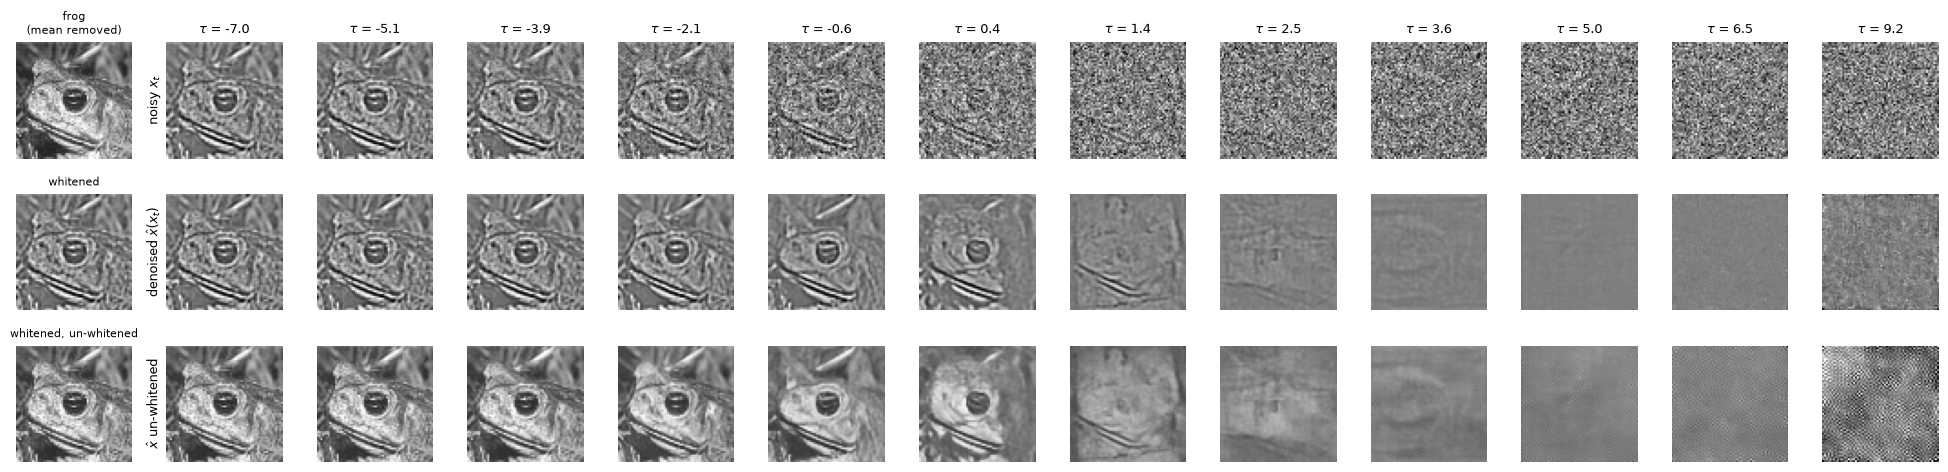

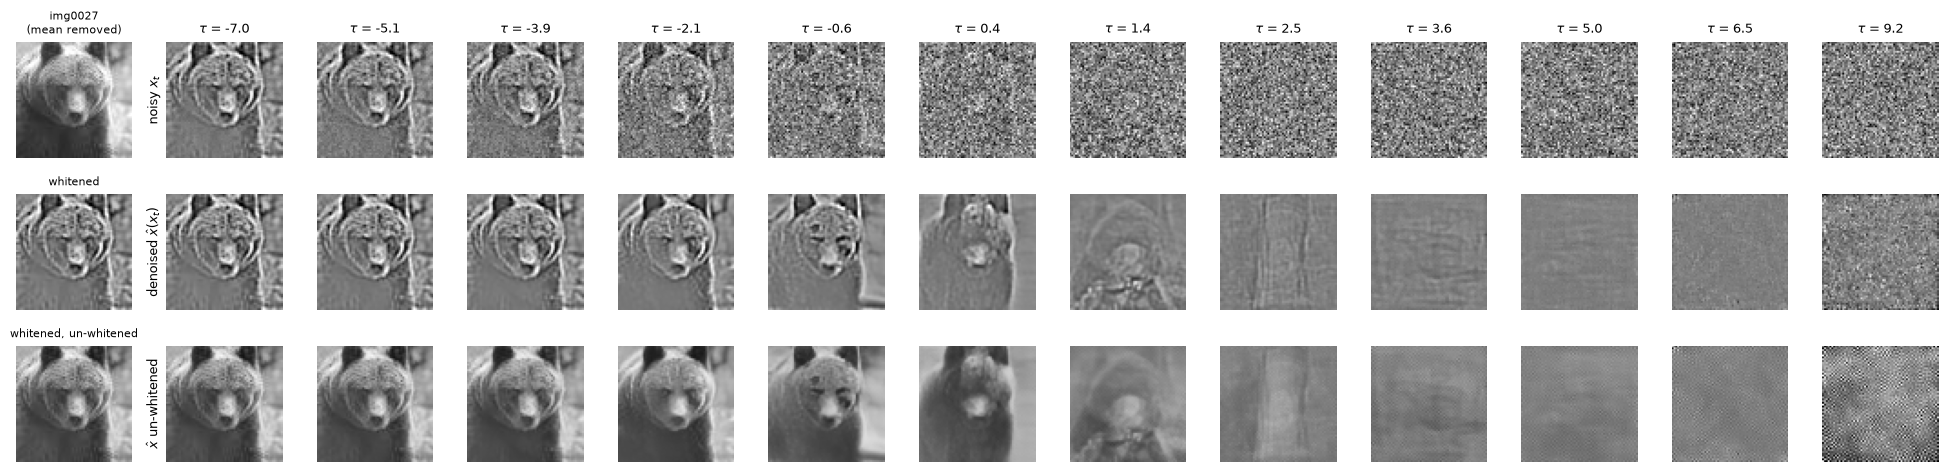

In [6]:
%%time

# one figure per image, saved; only those of PARAMS["show"] stay in the notebook
figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
for name, (image, _) in examples.items():
    white = whitening(image)
    fig, _ = plot_recovered(
        image, white, references[name], recovered[name], name, PARAMS
    )
    fig.savefig(
        figure_dir / f"recovered_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)
print(len(examples), "figures saved in", figure_dir)

## 6. Conclusion

* **The inverse filter works.** The whitened images un-whitened correlate at 0.985 with the images (mean removed, over the 33 images: the 13 of notebooks 8 and 16 and 20 more): almost everything but the mean comes back.
* **What the denoiser recovers falls steadily with the noise.** The correlation of the un-whitened denoised image with the image is 0.98 at $\tau = -7$, 0.92 at $-2.1$, 0.74 at 0.4, 0.55 at 1.4, 0.35 at 2.5, 0.20 at 3.6, and about 0 from $\tau \approx 6.5$ on. It varies a lot between images at middle scales: at $\tau = 0.4$ the mean is 0.74, but the lowest image is at 0.20.
* **From fine to coarse, the recovered image loses detail first.** In the frog's figure, fine texture goes first ($\tau \approx -2$ to 0), then edges, while the eye and the main shapes remain up to $\tau \approx 1.4$; at $\tau \ge 3.6$ only a faint blurred outline is left, then a uniform guess.
* **At the coarsest scale the denoised image is grainy** ($\tau = 9.2$): a checkerboard-like pattern that the network produces there, which the inverse filter amplifies; it does not come from the image (its correlation with the image is about 0).
* **Next steps.** Compare with the same curve for the model of the raw images (notebook 8's), to see whether whitening moves the recovery to finer scales, as the stimulus features of notebook 16 suggest.